# Multi-Terminal 2D Networks: Porting the 3D Generalization Down a Dimension

Both `percolation_3d_multi_terminal_faces.ipynb` and `percolation_3d_spherical_terminals.ipynb` generalize the single source/drain 2-terminal pipeline (`percolation_3d.ipynb`) to **several independent terminals, each with its own prescribed voltage**. Everything those two notebooks build on -- `path_analysis.py`, `pruning.py`, `impedance_calculator.py` (`merge_terminal_groups`, `_infer_dim`), `multi_terminal_solver.py` (`solve_multi_terminal`, `assign_nodes_to_spherical_terminals`, `assign_terminal_voltages`, `validate_multi_terminal_percolation`) -- was already dimension-agnostic, by their own docstrings: it operates on coordinate tuples of whatever length, 2 or 3, unchanged.

Only two pieces were actually hardwired to 3D, and both got 2D siblings for this notebook (added to the existing files, nothing else in `utils/` changed except exposing the `pre_merge_*` fields on `run_full_pipeline` that `run_full_pipeline_3d` already exposed -- needed so the multi-terminal pipelines can reuse it without duplicating contact-detection/percolation/pruning/rebuild logic):
- `multi_terminal_solver.split_face_into_quadrants` subdivides a source/drain face by `(y, z)` -- meaningless in 2D, since there's no `z`. Its 2D sibling, `split_face_into_segments`, subdivides by `y` alone (the only axis left on a face that's already fixed at `x<0.1` or `x>0.9`).
- `network_visualization_3d.plot_network_3d_colored_by_voltage` has a 2D sibling, `network_visualization.plot_network_colored_by_voltage`.

`pipeline_utils.run_full_pipeline_multi_terminal_faces` and `pipeline_utils.run_full_pipeline_circular_terminals` are the 2D analogs of `run_full_pipeline_3d_multi_terminal_faces` and `run_full_pipeline_3d_spherical_terminals` ("circular" instead of "spherical" -- a terminal region in the plane is a disk, not a sphere; the underlying `assign_nodes_to_spherical_terminals` helper is reused unchanged since it's just a Euclidean-distance check, dimension-agnostic despite its name).

Structure mirrors both 3D notebooks: validation first (identical math, dimension doesn't matter), then subdivided-face terminals, then terminals placed anywhere in the unit square. Random-network generation follows the same style as `test_150_random_networks.ipynb` / `test_random_network_impedance.ipynb`.

---
## 1. Setup and imports

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")

Environment: Local
Utils path: <project_root>/utils


In [2]:
from point_generator import generate_points
from pipeline_utils import run_full_pipeline_multi_terminal_faces, run_full_pipeline_circular_terminals
from multi_terminal_solver import (
    solve_multi_terminal, multi_terminal_pinv_currents,
    assign_nodes_to_spherical_terminals, validate_multi_terminal_percolation,
    print_terminal_roles,
)
from path_analysis import connected_components
from network_visualization import plot_network_colored_by_voltage, plot_network_colored_by_resistance

print("Imports OK")

Imports OK


---
## Experiment tracking

In [3]:
from experiment_manager import setup_experiment

exp_manager = setup_experiment()

EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 811
  Timestamp: 20260727_135832
  Results directory: <project_root>/utils/../experiments/exp_811



---
## 2. Validation: hand-built networks with a known answer

Same two validation cases as both 3D notebooks -- they exercise `solve_multi_terminal` directly and the math doesn't depend on dimension, so they're identical here except the coordinates are 2-tuples instead of 3-tuples (repeated for a self-contained notebook).

### 2.1 Three-terminal star (closed-form check)

One internal node connected to 3 terminals by edges of different lengths (distance-dependent resistance: `R_i = R0 * L_i`):

`Vc = (V1/R1 + V2/R2 + V3/R3) / (1/R1 + 1/R2 + 1/R3)`

In [4]:
intersections = [(0.5, 0.5), (0, 0), (2, 0), (0, 3)]
segment_to_nodes = {0: (0, 1), 1: (0, 2), 2: (0, 3)}
terminal_nodes = [1, 2, 3]
terminal_voltages = [1.0, 0.0, 0.6]
R0 = 1000.0

lengths = [np.linalg.norm(np.array(intersections[0]) - np.array(intersections[t])) for t in terminal_nodes]
expected_Vc = sum(v / L for v, L in zip(terminal_voltages, lengths)) / sum(1 / L for L in lengths)

res_star = solve_multi_terminal(intersections, segment_to_nodes, terminal_nodes, terminal_voltages,
                                k=R0, distance_dependent=True)

print(f"Internal node voltage: computed={res_star['voltages'][0]:.6f}  expected={expected_Vc:.6f}")
print(f"Current imbalance: {res_star['current_imbalance']:.2e} (should be ~0)")
assert abs(res_star['voltages'][0] - expected_Vc) < 1e-9
assert abs(res_star['current_imbalance']) < 1e-9
print("OK: matches the closed-form nodal-analysis formula exactly")

Internal node voltage: computed=0.676351  expected=0.676351
Current imbalance: 8.81e-20 (should be ~0)
OK: matches the closed-form nodal-analysis formula exactly


### 2.2 Four-terminal network with a loop (pseudoinverse cross-check)

Two internal nodes (A, B), 4 terminals arranged around a unit square, one bridging edge -- a genuine cycle, cross-checked against `multi_terminal_pinv_currents` (independently-coded, no `build_incidence_matrix`).

In [5]:
intersections_g = [(0.3, 0.5), (0, 0), (0, 1), (1, 1), (1, 0), (0.7, 0.5)]
# node indices: 0=A (internal), 1=T1, 2=T2, 3=T3, 4=T4, 5=B (internal)
segment_to_nodes_g = {0: (1, 0), 1: (2, 0), 2: (0, 5), 3: (5, 3), 4: (5, 4), 5: (1, 5)}
terminal_nodes_g = [1, 2, 3, 4]
terminal_voltages_g = [1.0, 0.3, 0.0, 0.7]

res_grid = solve_multi_terminal(intersections_g, segment_to_nodes_g, terminal_nodes_g, terminal_voltages_g,
                                k=R0, distance_dependent=True)
res_grid_pinv = multi_terminal_pinv_currents(intersections_g, segment_to_nodes_g, terminal_nodes_g, terminal_voltages_g,
                                             k=R0, distance_dependent=True)

print(f"Internal voltages (A, B): solver={res_grid['voltages'][0]:.6f}, {res_grid['voltages'][5]:.6f}")
print(f"                          pinv  ={res_grid_pinv['voltages'][0]:.6f}, {res_grid_pinv['voltages'][5]:.6f}")
print(f"Current imbalance: {res_grid['current_imbalance']:.2e} (should be ~0)")

assert np.allclose(res_grid['voltages'], res_grid_pinv['voltages'], atol=1e-9)
assert abs(res_grid['current_imbalance']) < 1e-9
for t in terminal_nodes_g:
    assert abs(res_grid['terminal_currents'][t] - res_grid_pinv['terminal_currents'][t]) < 1e-9
print("OK: matches the independent pseudoinverse solver exactly")

Internal voltages (A, B): solver=0.606565, 0.546973
                          pinv  =0.606565, 0.546973
Current imbalance: -3.25e-19 (should be ~0)
OK: matches the independent pseudoinverse solver exactly


### 2.3 Degenerate case: an isolated terminal must be rejected before solving

A "terminal" placed far from everything else (radius too small to reach any contact) must be caught by `validate_multi_terminal_percolation` -- confirming the validity check actually catches the case it's meant to catch, rather than silently reaching `solve_multi_terminal` with a meaningless answer.

Unlike the 3D notebook (which calls `identify_contacts_3d` on two nearly-touching sticks -- 3D contacts are proximity-based, via `contact_distance`), 2D sticks either cross at an exact geometric point or they don't, so the single contact node used here is built directly rather than through `identify_intersections` -- the point being tested is downstream of contact detection anyway.

In [6]:
# One real contact node, from the crossing of sticks 0 and 1, plus a terminal
# placed at (0.5, 0.5) with a radius far too small to reach it.
inter_pts = [(0.0, 0.0)]
graph = [(0, 1)]
print(f"Contacts: {len(inter_pts)}  (one, at the origin)")

terminal_groups_bad = assign_nodes_to_spherical_terminals(
    inter_pts, terminal_centers=[(0, 0), (0.5, 0.5)], terminal_radii=[0.2, 0.05]
)
print(f"Terminal group sizes: {[len(g) for g in terminal_groups_bad]}  (second terminal should be empty)")

components = connected_components(graph)
node_to_component = {n: c for c, comp in enumerate(components) for n in comp}
is_valid = validate_multi_terminal_percolation(terminal_groups_bad, node_to_component)
print(f"validate_multi_terminal_percolation: {is_valid}  (must be False)")
assert not is_valid
print("OK: the isolated/empty terminal is correctly rejected before any solve is attempted")

Contacts: 1  (one, at the origin)
Terminal group sizes: [1, 0]  (second terminal should be empty)
validate_multi_terminal_percolation: False  (must be False)
OK: the isolated/empty terminal is correctly rejected before any solve is attempted


---
## 3. Application to real random 2D networks

Two variants, matching the two 3D notebooks:
- **Subdivided boundary faces** (Sec. 3.1-3.2): keeps the `x<0.1`/`x>0.9` boundary convention, but each face -- a set of nodes that only varies in `y` in 2D -- is split into several independent terminals instead of merged into one, via `split_face_into_segments`.
- **Circular terminals anywhere** (Sec. 3.3-3.4): terminals are small disks placed anywhere in the unit square, not confined to the two faces, via `assign_nodes_to_spherical_terminals` + `connected_components` (no x-threshold, no single designated start node).

For the faces variant, ALL source-face segments get the same (high) voltage and ALL drain-face segments get the same (low) voltage by default -- not alternating `[1, 0, 1, 0, ...]` by list position, which would (whenever the two faces don't end up with matching non-empty-segment counts) assign the source's voltage to a drain-face segment, making it act as a second source despite sitting on the drain face. Voltages for the circular variant are hand-picked, same as the 3D notebook.

### 3.1 Subdivided boundary faces -- up to 4 terminals (2 segments/face)

Percolating multi-terminal network found on attempt 1
Terminals: 4 (out of up to 4 possible)   Voltages: [1.0, 1.0, 0.0, 0.0]
Terminal currents: {351: np.float64(-0.0003186308117326377), 352: np.float64(-0.00023903634605033875), 353: np.float64(0.00032727455833345755), 354: np.float64(0.0002303925994495211)}
Current imbalance: 2.22e-18 (should be ~0)
Terminal roles:
    node   351   V=+1.000   I=-3.186e-04   ->  SOURCE
    node   352   V=+1.000   I=-2.390e-04   ->  SOURCE
    node   353   V=+0.000   I=+3.273e-04   <-  DRAIN
    node   354   V=+0.000   I=+2.304e-04   <-  DRAIN


<project_root>/utils/impedance_calculator.py:575: RuntimeWarning: divide by zero encountered in matmul
  L = A.T @ G_matrix @ A
<project_root>/utils/impedance_calculator.py:575: RuntimeWarning: overflow encountered in matmul
  L = A.T @ G_matrix @ A
<project_root>/utils/impedance_calculator.py:575: RuntimeWarning: invalid value encountered in matmul
  L = A.T @ G_matrix @ A
<project_root>/utils/impedance_calculator.py:679: RuntimeWarning: divide by zero encountered in matmul
  voltage_drops = -A @ V_full  # Voltage drop across each edge
<project_root>/utils/impedance_calculator.py:679: RuntimeWarning: overflow encountered in matmul
  voltage_drops = -A @ V_full  # Voltage drop across each edge
<project_root>/utils/impedance_calculator.py:679: RuntimeWarning: invalid value encountered in matmul
  voltage_drops = -A @ V_full  # Voltage drop across each edge
<project_root>/utils/impedance_calculator.py:680: RuntimeWarning: divide by zero encountered in matmul
  I = G_matrix @ voltage_drop

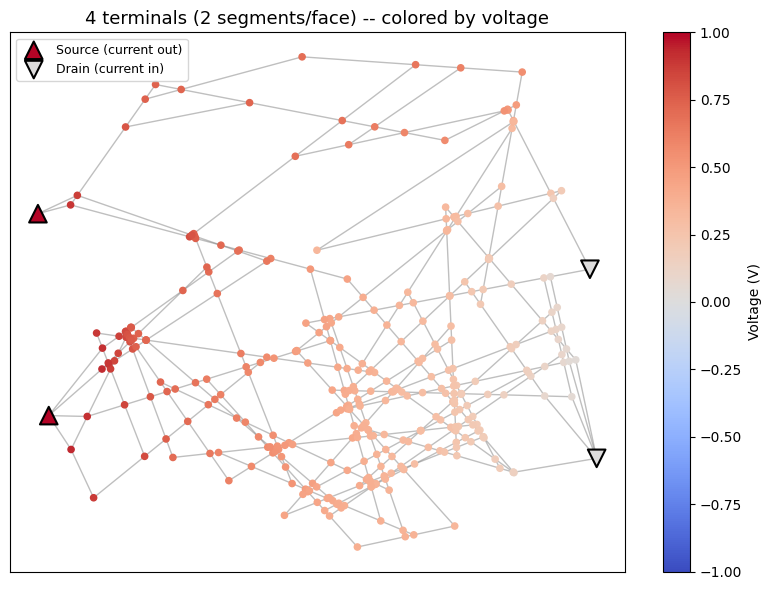

  [OK] Figure saved: faces2d_4terminals_voltage.png


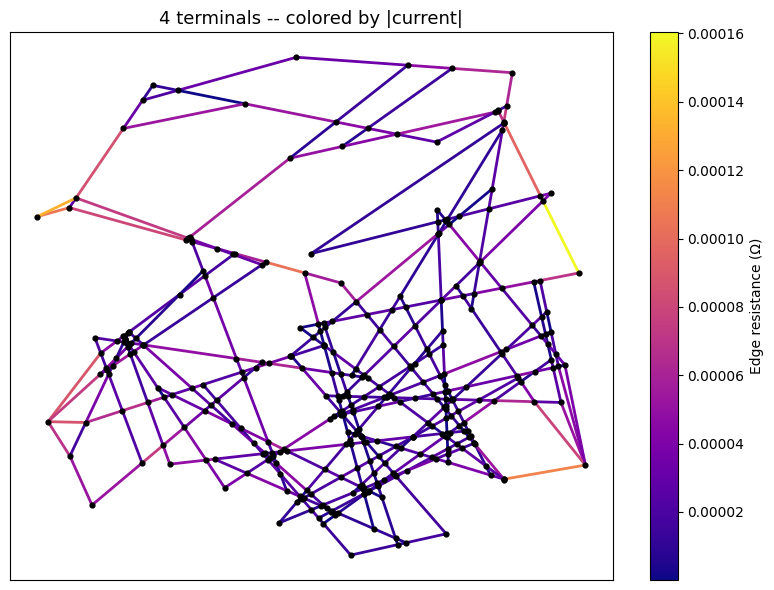

  [OK] Figure saved: faces2d_4terminals_current.png


'<project_root>/utils/../experiments/exp_811/faces2d_4terminals_current.png'

In [7]:
N4, a4 = 60, 0.5

np.random.seed(10)
points_1, points_2, angles = [], [], []
generate_points(N4, points_1, points_2, angles, a4, enforce_bounds=True)

res4 = None
for attempt in range(1, 51):
    res4 = run_full_pipeline_multi_terminal_faces(
        points_1, points_2, angles, N=N4, a=a4,
        n_subdivisions_per_face=2, k=1000.0, verbose=False,
    )
    if res4.get("has_percolation"):
        break
    points_1, points_2, angles = [], [], []
    generate_points(N4, points_1, points_2, angles, a4, enforce_bounds=True)

n_terminals_4 = len(res4['terminal_node_indices'])
print(f"Percolating multi-terminal network found on attempt {attempt}")
print(f"Terminals: {n_terminals_4} (out of up to 4 possible)   Voltages: {res4['terminal_voltages']}")
print(f"Terminal currents: {res4['solve']['terminal_currents']}")
print(f"Current imbalance: {res4['solve']['current_imbalance']:.2e} (should be ~0)")
assert abs(res4['solve']['current_imbalance']) < 1e-6 * max(abs(v) for v in res4['solve']['terminal_currents'].values())

print_terminal_roles(res4['terminal_node_indices'], res4['terminal_voltages'], res4['solve']['terminal_currents'],
                    title="Terminal roles:")

fig = plot_network_colored_by_voltage(
    res4["merged_intersections"], res4["merged_segment_to_nodes"], res4["solve"]["voltages"],
    terminal_nodes=res4["terminal_node_indices"], terminal_currents=res4["solve"]["terminal_currents"], title=f"{n_terminals_4} terminals (2 segments/face) -- colored by voltage"
)
plt.show()
exp_manager.save_figure(fig, "faces2d_4terminals_voltage.png")

fig2 = plot_network_colored_by_resistance(
    res4["merged_intersections"], res4["merged_segment_to_nodes"], np.abs(res4["solve"]["currents"]),
    title=f"{n_terminals_4} terminals -- colored by |current|", cmap_name="plasma"
)
plt.show()
exp_manager.save_figure(fig2, "faces2d_4terminals_current.png")

### 3.2 Subdivided boundary faces -- up to 8 terminals (4 segments/face)

<project_root>/utils/impedance_calculator.py:625: RuntimeWarning: divide by zero encountered in matmul
  b = -L_ib @ V_boundary
<project_root>/utils/impedance_calculator.py:625: RuntimeWarning: overflow encountered in matmul
  b = -L_ib @ V_boundary
<project_root>/utils/impedance_calculator.py:625: RuntimeWarning: invalid value encountered in matmul
  b = -L_ib @ V_boundary


Percolating multi-terminal network found on attempt 1
Terminals: 6 (out of up to 8 possible)   Voltages: [1.0, 1.0, 1.0, 0.0, 0.0, 0.0]
Terminal currents: {970: np.float64(-0.00014592256014984872), 971: np.float64(-0.00027512577711856403), 972: np.float64(-0.0002283039752314916), 973: np.float64(0.00020301733145410152), 974: np.float64(0.00026555702504902365), 975: np.float64(0.00018077795599647298)}
Current imbalance: -3.06e-16 (should be ~0)
Terminal roles:
    node   970   V=+1.000   I=-1.459e-04   ->  SOURCE
    node   971   V=+1.000   I=-2.751e-04   ->  SOURCE
    node   972   V=+1.000   I=-2.283e-04   ->  SOURCE
    node   973   V=+0.000   I=+2.030e-04   <-  DRAIN
    node   974   V=+0.000   I=+2.656e-04   <-  DRAIN
    node   975   V=+0.000   I=+1.808e-04   <-  DRAIN


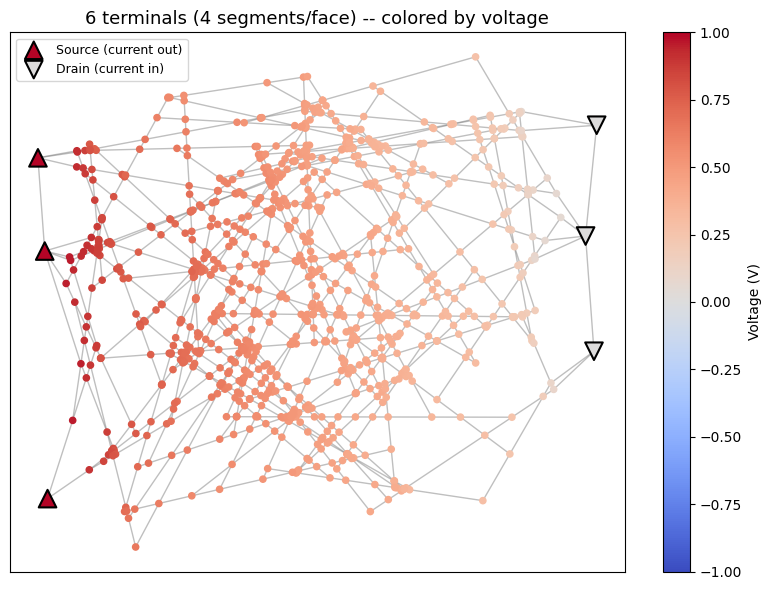

  [OK] Figure saved: faces2d_8terminals_voltage.png


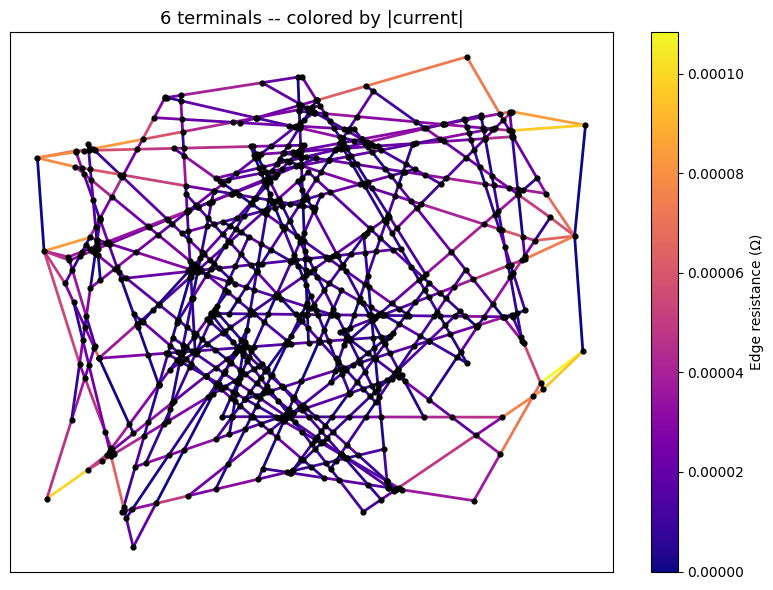

  [OK] Figure saved: faces2d_8terminals_current.png


'<project_root>/utils/../experiments/exp_811/faces2d_8terminals_current.png'

In [8]:
N8, a8 = 100, 0.5

np.random.seed(20)
points_1, points_2, angles = [], [], []
generate_points(N8, points_1, points_2, angles, a8, enforce_bounds=True)

res8 = None
for attempt in range(1, 51):
    res8 = run_full_pipeline_multi_terminal_faces(
        points_1, points_2, angles, N=N8, a=a8,
        n_subdivisions_per_face=4, k=1000.0, verbose=False,
    )
    if res8.get("has_percolation"):
        break
    points_1, points_2, angles = [], [], []
    generate_points(N8, points_1, points_2, angles, a8, enforce_bounds=True)

n_terminals_8 = len(res8['terminal_node_indices'])
print(f"Percolating multi-terminal network found on attempt {attempt}")
print(f"Terminals: {n_terminals_8} (out of up to 8 possible)   Voltages: {res8['terminal_voltages']}")
print(f"Terminal currents: {res8['solve']['terminal_currents']}")
print(f"Current imbalance: {res8['solve']['current_imbalance']:.2e} (should be ~0)")
assert abs(res8['solve']['current_imbalance']) < 1e-6 * max(abs(v) for v in res8['solve']['terminal_currents'].values())

print_terminal_roles(res8['terminal_node_indices'], res8['terminal_voltages'], res8['solve']['terminal_currents'],
                    title="Terminal roles:")

fig = plot_network_colored_by_voltage(
    res8["merged_intersections"], res8["merged_segment_to_nodes"], res8["solve"]["voltages"],
    terminal_nodes=res8["terminal_node_indices"], terminal_currents=res8["solve"]["terminal_currents"], title=f"{n_terminals_8} terminals (4 segments/face) -- colored by voltage"
)
plt.show()
exp_manager.save_figure(fig, "faces2d_8terminals_voltage.png")

fig2 = plot_network_colored_by_resistance(
    res8["merged_intersections"], res8["merged_segment_to_nodes"], np.abs(res8["solve"]["currents"]),
    title=f"{n_terminals_8} terminals -- colored by |current|", cmap_name="plasma"
)
plt.show()
exp_manager.save_figure(fig2, "faces2d_8terminals_current.png")

### 3.3 Circular terminals anywhere -- 3 terminals

Percolating multi-terminal network found on attempt 1
Terminal currents: {158: np.float64(-0.0015249789523348403), 159: np.float64(0.0016844486522935185), 160: np.float64(-0.00015946969995867904)}
Current imbalance: -8.13e-19 (should be ~0)
Terminal roles:
    node   158   V=+1.000   I=-1.525e-03   ->  SOURCE
    node   159   V=+0.000   I=+1.684e-03   <-  DRAIN
    node   160   V=+0.500   I=-1.595e-04   ->  SOURCE


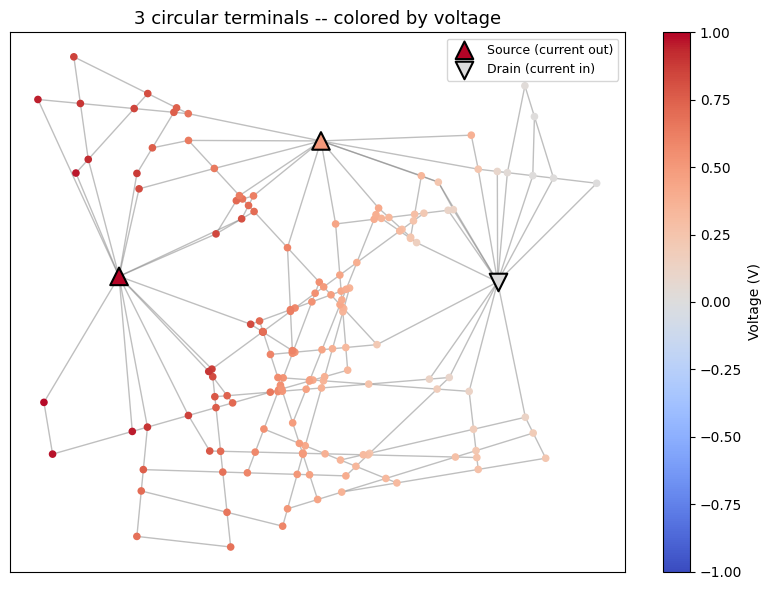

  [OK] Figure saved: circular2d_3terminals_voltage.png


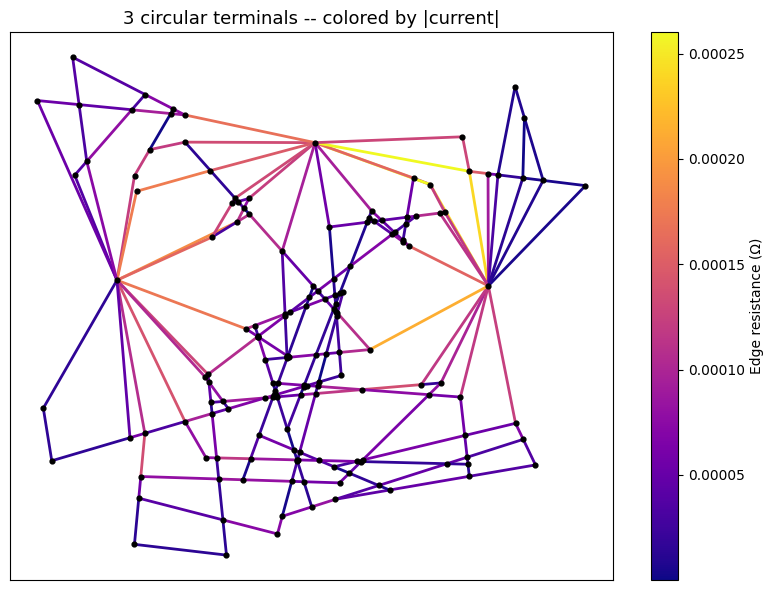

  [OK] Figure saved: circular2d_3terminals_current.png


'<project_root>/utils/../experiments/exp_811/circular2d_3terminals_current.png'

In [9]:
N3, a3 = 60, 0.5
centers3 = [(0.15, 0.5), (0.85, 0.5), (0.5, 0.85)]
radii3 = [0.2, 0.2, 0.2]
voltages3 = [1.0, 0.0, 0.5]

np.random.seed(30)
points_1, points_2, angles = [], [], []
generate_points(N3, points_1, points_2, angles, a3, enforce_bounds=True)

res3 = None
for attempt in range(1, 31):
    res3 = run_full_pipeline_circular_terminals(
        points_1, points_2, angles, N=N3, a=a3,
        terminal_centers=centers3, terminal_radii=radii3, terminal_voltages=voltages3,
        k=1000.0, verbose=False,
    )
    if res3.get("has_percolation"):
        break
    points_1, points_2, angles = [], [], []
    generate_points(N3, points_1, points_2, angles, a3, enforce_bounds=True)

print(f"Percolating multi-terminal network found on attempt {attempt}")
print(f"Terminal currents: {res3['solve']['terminal_currents']}")
print(f"Current imbalance: {res3['solve']['current_imbalance']:.2e} (should be ~0)")
assert abs(res3['solve']['current_imbalance']) < 1e-6 * max(abs(v) for v in res3['solve']['terminal_currents'].values())

print_terminal_roles(res3['terminal_node_indices'], res3['terminal_voltages'], res3['solve']['terminal_currents'],
                    title="Terminal roles:")

fig = plot_network_colored_by_voltage(
    res3["merged_intersections"], res3["merged_segment_to_nodes"], res3["solve"]["voltages"],
    terminal_nodes=res3["terminal_node_indices"], terminal_currents=res3["solve"]["terminal_currents"], title="3 circular terminals -- colored by voltage"
)
plt.show()
exp_manager.save_figure(fig, "circular2d_3terminals_voltage.png")

fig2 = plot_network_colored_by_resistance(
    res3["merged_intersections"], res3["merged_segment_to_nodes"], np.abs(res3["solve"]["currents"]),
    title="3 circular terminals -- colored by |current|", cmap_name="plasma"
)
plt.show()
exp_manager.save_figure(fig2, "circular2d_3terminals_current.png")

### 3.4 Circular terminals anywhere -- 5 terminals, including one at the center

Percolating multi-terminal network found on attempt 1
Terminal currents: {425: np.float64(-0.00247186555582766), 426: np.float64(0.0021425534486457375), 427: np.float64(-0.0005986022851018827), 428: np.float64(0.0006835090024683445), 429: np.float64(0.00024440538981546474)}
Current imbalance: 3.96e-18 (should be ~0)
Terminal roles:
    node   425   V=+1.000   I=-2.472e-03   ->  SOURCE
    node   426   V=+0.000   I=+2.143e-03   <-  DRAIN
    node   427   V=+0.700   I=-5.986e-04   ->  SOURCE
    node   428   V=+0.300   I=+6.835e-04   <-  DRAIN
    node   429   V=+0.500   I=+2.444e-04   <-  DRAIN


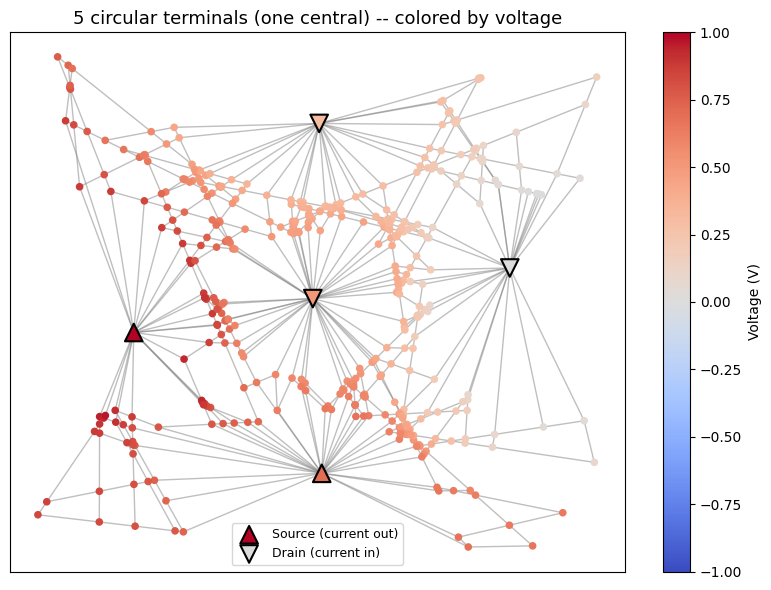

  [OK] Figure saved: circular2d_5terminals_voltage.png


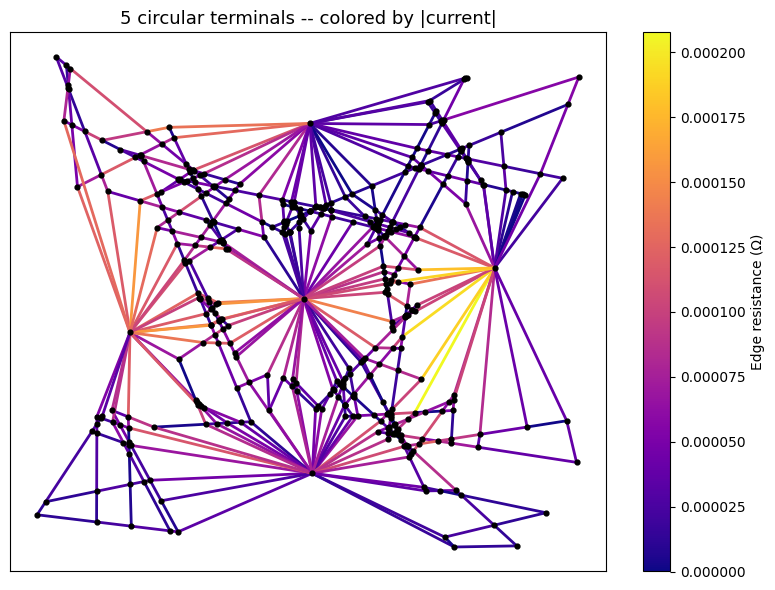

  [OK] Figure saved: circular2d_5terminals_current.png


'<project_root>/utils/../experiments/exp_811/circular2d_5terminals_current.png'

In [10]:
N5, a5 = 100, 0.5
centers5 = [(0.15, 0.5), (0.85, 0.5), (0.5, 0.15), (0.5, 0.85), (0.5, 0.5)]
radii5 = [0.18, 0.18, 0.18, 0.18, 0.12]
voltages5 = [1.0, 0.0, 0.7, 0.3, 0.5]

np.random.seed(40)
points_1, points_2, angles = [], [], []
generate_points(N5, points_1, points_2, angles, a5, enforce_bounds=True)

res5 = None
for attempt in range(1, 31):
    res5 = run_full_pipeline_circular_terminals(
        points_1, points_2, angles, N=N5, a=a5,
        terminal_centers=centers5, terminal_radii=radii5, terminal_voltages=voltages5,
        k=1000.0, verbose=False,
    )
    if res5.get("has_percolation"):
        break
    points_1, points_2, angles = [], [], []
    generate_points(N5, points_1, points_2, angles, a5, enforce_bounds=True)

print(f"Percolating multi-terminal network found on attempt {attempt}")
print(f"Terminal currents: {res5['solve']['terminal_currents']}")
print(f"Current imbalance: {res5['solve']['current_imbalance']:.2e} (should be ~0)")
assert abs(res5['solve']['current_imbalance']) < 1e-6 * max(abs(v) for v in res5['solve']['terminal_currents'].values())

print_terminal_roles(res5['terminal_node_indices'], res5['terminal_voltages'], res5['solve']['terminal_currents'],
                    title="Terminal roles:")

fig = plot_network_colored_by_voltage(
    res5["merged_intersections"], res5["merged_segment_to_nodes"], res5["solve"]["voltages"],
    terminal_nodes=res5["terminal_node_indices"], terminal_currents=res5["solve"]["terminal_currents"], title="5 circular terminals (one central) -- colored by voltage"
)
plt.show()
exp_manager.save_figure(fig, "circular2d_5terminals_voltage.png")

fig2 = plot_network_colored_by_resistance(
    res5["merged_intersections"], res5["merged_segment_to_nodes"], np.abs(res5["solve"]["currents"]),
    title="5 circular terminals -- colored by |current|", cmap_name="plasma"
)
plt.show()
exp_manager.save_figure(fig2, "circular2d_5terminals_current.png")

### 3.5 Subdivided boundary faces -- odd subdivision count (3 segments/face)

Different from 3.1/3.2 in a way that's actually 2D-specific: `split_face_into_segments` (unlike its 3D sibling `split_face_into_quadrants`, restricted to 2 or 4) accepts ANY `n_subdivisions >= 2`, since a 2D face is split along a single axis (`y`) instead of a `(y, z)` quadrant grid. `n_subdivisions_per_face=3` -- an odd, non-power-of-2 split with no 3D equivalent -- exercises that extra flexibility, on a denser/smaller-stick network than 3.1/3.2.

Percolating multi-terminal network found on attempt 1
Terminals: 5 (out of up to 6 possible)   Voltages: [1.0, 1.0, 1.0, 0.0, 0.0]
Terminal currents: {774: np.float64(-0.00010075416727504727), 775: np.float64(-0.0002835871873722067), 776: np.float64(-0.00022973306103396996), 777: np.float64(0.00042012931498328033), 778: np.float64(0.00019394510069780985)}
Current imbalance: -1.34e-16 (should be ~0)
Terminal roles:
    node   774   V=+1.000   I=-1.008e-04   ->  SOURCE
    node   775   V=+1.000   I=-2.836e-04   ->  SOURCE
    node   776   V=+1.000   I=-2.297e-04   ->  SOURCE
    node   777   V=+0.000   I=+4.201e-04   <-  DRAIN
    node   778   V=+0.000   I=+1.939e-04   <-  DRAIN


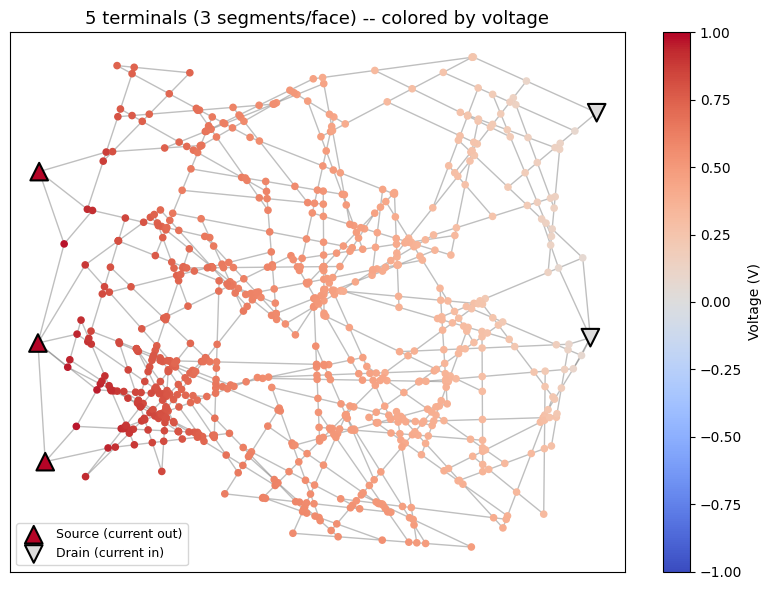

  [OK] Figure saved: faces2d_odd_voltage.png


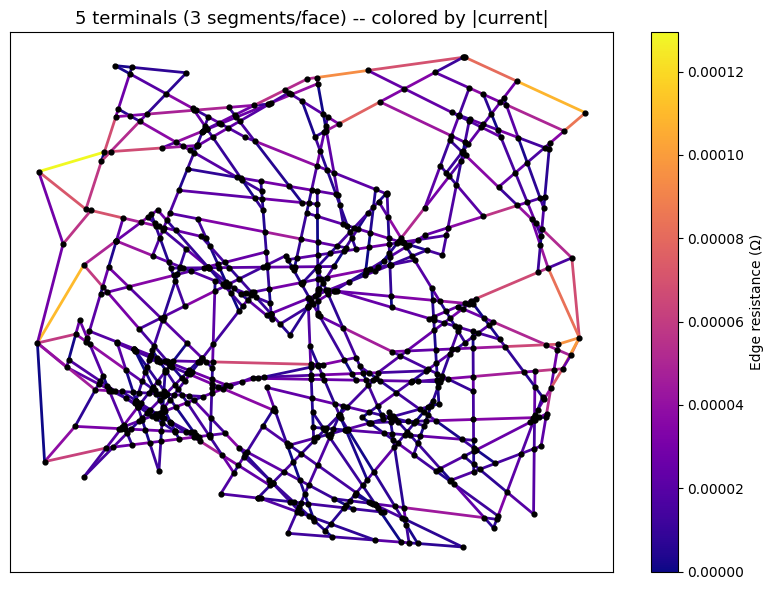

  [OK] Figure saved: faces2d_odd_current.png


'<project_root>/utils/../experiments/exp_811/faces2d_odd_current.png'

In [11]:
N_odd, a_odd = 150, 0.3

np.random.seed(50)
points_1, points_2, angles = [], [], []
generate_points(N_odd, points_1, points_2, angles, a_odd, enforce_bounds=True)

res_odd = None
for attempt in range(1, 51):
    res_odd = run_full_pipeline_multi_terminal_faces(
        points_1, points_2, angles, N=N_odd, a=a_odd,
        n_subdivisions_per_face=3, k=1000.0, verbose=False,
    )
    if res_odd.get("has_percolation"):
        break
    points_1, points_2, angles = [], [], []
    generate_points(N_odd, points_1, points_2, angles, a_odd, enforce_bounds=True)

n_terminals_odd = len(res_odd['terminal_node_indices'])
print(f"Percolating multi-terminal network found on attempt {attempt}")
print(f"Terminals: {n_terminals_odd} (out of up to 6 possible)   Voltages: {res_odd['terminal_voltages']}")
print(f"Terminal currents: {res_odd['solve']['terminal_currents']}")
print(f"Current imbalance: {res_odd['solve']['current_imbalance']:.2e} (should be ~0)")
assert abs(res_odd['solve']['current_imbalance']) < 1e-6 * max(abs(v) for v in res_odd['solve']['terminal_currents'].values())

print_terminal_roles(res_odd['terminal_node_indices'], res_odd['terminal_voltages'], res_odd['solve']['terminal_currents'],
                    title="Terminal roles:")

fig = plot_network_colored_by_voltage(
    res_odd["merged_intersections"], res_odd["merged_segment_to_nodes"], res_odd["solve"]["voltages"],
    terminal_nodes=res_odd["terminal_node_indices"], terminal_currents=res_odd["solve"]["terminal_currents"], title=f"{n_terminals_odd} terminals (3 segments/face) -- colored by voltage"
)
plt.show()
exp_manager.save_figure(fig, "faces2d_odd_voltage.png")

fig2 = plot_network_colored_by_resistance(
    res_odd["merged_intersections"], res_odd["merged_segment_to_nodes"], np.abs(res_odd["solve"]["currents"]),
    title=f"{n_terminals_odd} terminals (3 segments/face) -- colored by |current|", cmap_name="plasma"
)
plt.show()
exp_manager.save_figure(fig2, "faces2d_odd_current.png")


### 3.6 Circular terminals anywhere -- six terminals in a ring, no terminal at the center

Different arrangement from 3.3/3.4: six terminals placed roughly on a hexagon around the square's center (none of them AT the center this time), voltages set to alternate high/low around the ring rather than being hand-tuned individually.

Percolating multi-terminal network found on attempt 1
Terminal currents: {170: np.float64(-0.0051326047421780836), 171: np.float64(0.005913921350737859), 172: np.float64(-0.005026803030344553), 173: np.float64(0.005863019835610115), 174: np.float64(-0.003908771364929997), 175: np.float64(0.002291237951104666)}
Current imbalance: 6.07e-18 (should be ~0)
Terminal roles:
    node   170   V=+1.000   I=-5.133e-03   ->  SOURCE
    node   171   V=+0.000   I=+5.914e-03   <-  DRAIN
    node   172   V=+1.000   I=-5.027e-03   ->  SOURCE
    node   173   V=+0.000   I=+5.863e-03   <-  DRAIN
    node   174   V=+1.000   I=-3.909e-03   ->  SOURCE
    node   175   V=+0.000   I=+2.291e-03   <-  DRAIN


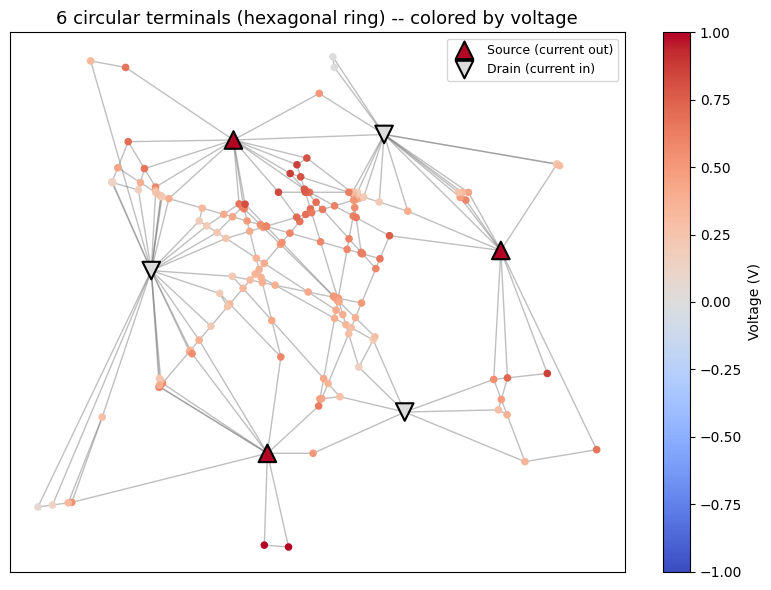

  [OK] Figure saved: circular2d_6terminals_voltage.png


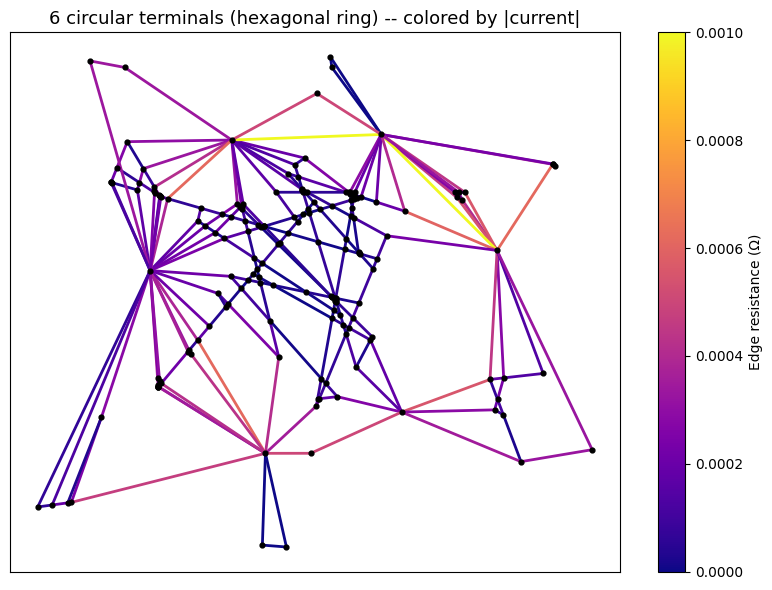

  [OK] Figure saved: circular2d_6terminals_current.png


'<project_root>/utils/../experiments/exp_811/circular2d_6terminals_current.png'

In [12]:
N6, a6 = 60, 0.5
angles6 = np.linspace(0, 2 * np.pi, 6, endpoint=False)
centers6 = [(0.5 + 0.32 * np.cos(t), 0.5 + 0.32 * np.sin(t)) for t in angles6]
radii6 = [0.15] * 6
voltages6 = [1.0 if i % 2 == 0 else 0.0 for i in range(6)]

np.random.seed(60)
points_1, points_2, angles = [], [], []
generate_points(N6, points_1, points_2, angles, a6, enforce_bounds=True)

res6 = None
for attempt in range(1, 31):
    res6 = run_full_pipeline_circular_terminals(
        points_1, points_2, angles, N=N6, a=a6,
        terminal_centers=centers6, terminal_radii=radii6, terminal_voltages=voltages6,
        k=1000.0, verbose=False,
    )
    if res6.get("has_percolation"):
        break
    points_1, points_2, angles = [], [], []
    generate_points(N6, points_1, points_2, angles, a6, enforce_bounds=True)

print(f"Percolating multi-terminal network found on attempt {attempt}")
print(f"Terminal currents: {res6['solve']['terminal_currents']}")
print(f"Current imbalance: {res6['solve']['current_imbalance']:.2e} (should be ~0)")
assert abs(res6['solve']['current_imbalance']) < 1e-6 * max(abs(v) for v in res6['solve']['terminal_currents'].values())

print_terminal_roles(res6['terminal_node_indices'], res6['terminal_voltages'], res6['solve']['terminal_currents'],
                    title="Terminal roles:")

fig = plot_network_colored_by_voltage(
    res6["merged_intersections"], res6["merged_segment_to_nodes"], res6["solve"]["voltages"],
    terminal_nodes=res6["terminal_node_indices"], terminal_currents=res6["solve"]["terminal_currents"], title="6 circular terminals (hexagonal ring) -- colored by voltage"
)
plt.show()
exp_manager.save_figure(fig, "circular2d_6terminals_voltage.png")

fig2 = plot_network_colored_by_resistance(
    res6["merged_intersections"], res6["merged_segment_to_nodes"], np.abs(res6["solve"]["currents"]),
    title="6 circular terminals (hexagonal ring) -- colored by |current|", cmap_name="plasma"
)
plt.show()
exp_manager.save_figure(fig2, "circular2d_6terminals_current.png")


---
## Notes

- Every piece reused here unchanged from 3D (`path_analysis.py`, `pruning.py`, `impedance_calculator.py`, `multi_terminal_solver.solve_multi_terminal`/`assign_nodes_to_spherical_terminals`/`assign_terminal_voltages`/`validate_multi_terminal_percolation`) confirms those modules really were dimension-agnostic, not just documented as such.
- `current_imbalance ≈ 0` is checked everywhere -- a hard conservation law (Kirchhoff's current law on the whole network), independent of terminal count, placement, topology, or dimension. Note this check alone can't catch a terminal being assigned the wrong electrical role -- global conservation holds regardless, since it's just a re-partition of the same globally-zero current sum (see next bullet).
- For the faces variant, the default `terminal_voltages` (when none is passed) is face-consistent: all non-empty source-face segments get 1.0, all non-empty drain-face segments get 0.0. An earlier version alternated `[1, 0, 1, 0, ...]` by list position across `source_groups + drain_groups`, which (whenever the two faces ended up with different non-empty-segment counts) could assign the source's voltage to a drain-face segment -- making it electrically act as a second source and creating a spurious internal current between two segments of the same physical face, silently inflating the apparent effective resistance of the network. Fixed since it directly undermined comparability with the plain 2-terminal case.
- Terminal role (source vs. drain) isn't something you set -- you only prescribe `terminal_voltages`. It's read off the *sign* of `solve['terminal_currents'][node]`: negative means current flows out of that terminal into the network (source), positive means current flows in from the network (drain). The highest/lowest-voltage terminals reliably end up source/drain; terminals at intermediate voltages can go either way depending on network topology -- see the mixed signs in Sections 3.3/3.4.
- Empty terminal segments (no contact nodes in that sub-region of a face) are silently dropped by default (`drop_empty_terminals=True`), same as the 3D faces notebook -- why the printed terminal count can be less than `2 x n_subdivisions_per_face`.
- 2D percolates far more readily than 3D for the same `(N, a)`, so `N`/`a` here are smaller than the 3D notebooks' -- chosen empirically so most seeds percolate on the first or second attempt.

---
## 4. Save consolidated summary

In [13]:
summary = {
    "experiment": exp_manager.get_info(),
    "validation": {
        "star_Vc": res_star["voltages"][0],
        "star_Vc_expected": expected_Vc,
        "grid_current_imbalance": res_grid["current_imbalance"],
        "isolated_terminal_correctly_rejected": not is_valid,
    },
    "faces_4terminal_network": {
        "N": N4, "a": a4,
        "terminal_voltages": res4["terminal_voltages"],
        "terminal_currents": {str(k): v for k, v in res4["solve"]["terminal_currents"].items()},
        "current_imbalance": res4["solve"]["current_imbalance"],
    },
    "faces_8terminal_network": {
        "N": N8, "a": a8,
        "terminal_voltages": res8["terminal_voltages"],
        "terminal_currents": {str(k): v for k, v in res8["solve"]["terminal_currents"].items()},
        "current_imbalance": res8["solve"]["current_imbalance"],
    },
    "faces_odd_subdivision_network": {
        "N": N_odd, "a": a_odd,
        "terminal_voltages": res_odd["terminal_voltages"],
        "terminal_currents": {str(k): v for k, v in res_odd["solve"]["terminal_currents"].items()},
        "current_imbalance": res_odd["solve"]["current_imbalance"],
    },
    "circular_3terminal_network": {
        "N": N3, "a": a3,
        "terminal_centers": centers3, "terminal_radii": radii3,
        "terminal_voltages": res3["terminal_voltages"],
        "terminal_currents": {str(k): v for k, v in res3["solve"]["terminal_currents"].items()},
        "current_imbalance": res3["solve"]["current_imbalance"],
    },
    "circular_5terminal_network": {
        "N": N5, "a": a5,
        "terminal_centers": centers5, "terminal_radii": radii5,
        "terminal_voltages": res5["terminal_voltages"],
        "terminal_currents": {str(k): v for k, v in res5["solve"]["terminal_currents"].items()},
        "current_imbalance": res5["solve"]["current_imbalance"],
    },
    "circular_6terminal_ring_network": {
        "N": N6, "a": a6,
        "terminal_centers": centers6, "terminal_radii": radii6,
        "terminal_voltages": res6["terminal_voltages"],
        "terminal_currents": {str(k): v for k, v in res6["solve"]["terminal_currents"].items()},
        "current_imbalance": res6["solve"]["current_imbalance"],
    },
}

exp_manager.save_json(summary, "multi_terminal_2d_summary.json")

print(f"\nAll results saved to: {exp_manager.experiment_dir}")
for f in sorted(os.listdir(exp_manager.experiment_dir)):
    print(f"  - {f}")

  [OK] JSON saved: multi_terminal_2d_summary.json

All results saved to: <project_root>/utils/../experiments/exp_811
  - circular2d_3terminals_current.png
  - circular2d_3terminals_voltage.png
  - circular2d_5terminals_current.png
  - circular2d_5terminals_voltage.png
  - circular2d_6terminals_current.png
  - circular2d_6terminals_voltage.png
  - faces2d_4terminals_current.png
  - faces2d_4terminals_voltage.png
  - faces2d_8terminals_current.png
  - faces2d_8terminals_voltage.png
  - faces2d_odd_current.png
  - faces2d_odd_voltage.png
  - multi_terminal_2d_summary.json
